# EDA — Benchmark Dataset (`data-processed/`)

Phân tích thống kê tập benchmark IDP gồm **60 mẫu** trải trên 2 ngôn ngữ, 3 doc_type, 2 subtype.
Chart xuất ra `notebooks/figures/` để dùng trong thesis report.

> Lưu ý: tập con `Typed-Custom` (doc_type=`custom`, 1 mẫu nhãn dinh dưỡng) được **loại khỏi** phân tích này — chỉ giữ 3 loại tài liệu chính (invoice, contract, id_card).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Paths ──────────────────────────────────────────────────────────────────
# Notebook chạy trong notebooks/ → project root là thư mục cha.
# Fallback: nếu cwd đã là project root thì dùng luôn.
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (PROJECT_ROOT / "data-processed").exists():
    raise FileNotFoundError(
        f"Không tìm thấy data-processed/ trong {PROJECT_ROOT}. "
        "Hãy chạy notebook từ thư mục notebooks/ hoặc project root."
    )

DATA_DIR = PROJECT_ROOT / "data-processed"
FIG_DIR  = PROJECT_ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Style ───────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
PALETTE = {
    "EN": "#4C72B0",
    "VN": "#DD8452",
    "typed": "#4C72B0",
    "handwritten": "#C44E52",
    "invoice":  "#4C72B0",
    "contract": "#DD8452",
    "id_card":  "#55A868",
    "custom":   "#8172B2",
}

def save(name: str):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, bbox_inches="tight")
    print(f"Saved → {path}")

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print("Setup done.")

PROJECT_ROOT = D:\MasterDegree\LVTN
Setup done.


## 1. Load all ground-truth JSON files

In [2]:
import re

def infer_source(doc_name: str, dataset: str, lang: str) -> str:
    """Nguồn dữ liệu: 3 public dataset (SROIE/Kaggle/Roboflow) + phần tự bổ sung."""
    if dataset == "Typed-Invoice" and lang == "EN":
        # SROIE (X + chữ số) vs phần còn lại lấy từ Kaggle (invoice/receipt)
        return "SROIE" if re.match(r"^X\d{9,12}$", doc_name) else "Kaggle"
    if dataset == "Typed-Contract" and lang == "EN":
        return "Kaggle"
    if dataset == "Typed-IdCard" and lang == "VN":
        # CCCD Roboflow (*.rf.*) vs CCCD thực tự thu thập
        return "Roboflow" if ".rf." in doc_name else "Tự bổ sung thêm"
    # VN contract (cho vay + mở TK) do tự thu thập
    return "Tự bổ sung thêm"

rows = []
for jf in sorted(DATA_DIR.rglob("ground_truth/*.json")):
    with open(jf, encoding="utf-8") as f:
        d = json.load(f)
    if d["doc_type"] == "custom":      # loại custom khỏi benchmark — chỉ giữ 60 mẫu
        continue
    dataset = jf.parent.parent.name
    rows.append({
        "doc_name": d["doc_name"],
        "lang":     d["lang"],
        "doc_type": d["doc_type"],
        "subtype":  d["subtype"],
        "dataset":  dataset,
        "source":   infer_source(d["doc_name"], dataset, d["lang"]),
        "n_fields": len(d.get("fields", {})),
    })

df = pd.DataFrame(rows)
print(f"Total records: {len(df)}")
df.head()

Total records: 60


,doc_name,lang,doc_type,subtype,dataset,source,n_fields
0,CONTRACT_000003,EN,contract,typed,Typed-Contract,Kaggle,5
1,CONTRACT_000004,EN,contract,typed,Typed-Contract,Kaggle,5
2,CONTRACT_000011,EN,contract,typed,Typed-Contract,Kaggle,5
3,CONTRACT_000013,EN,contract,typed,Typed-Contract,Kaggle,5
4,CONTRACT_000014,EN,contract,typed,Typed-Contract,Kaggle,5


## 2. Summary statistics

In [3]:
print("=== By lang ===");    print(df.groupby("lang").size().to_string())
print("\n=== By doc_type ==="); print(df.groupby("doc_type").size().to_string())
print("\n=== By subtype ===");  print(df.groupby("subtype").size().to_string())
print("\n=== By dataset ===");  print(df.groupby("dataset").size().to_string())
print("\n=== By source ===");   print(df.groupby("source").size().sort_values(ascending=False).to_string())

=== By lang ===


lang
EN    40
VN    20

=== By doc_type ===
doc_type
contract    30
id_card     10
invoice     20

=== By subtype ===
subtype
handwritten     5
typed          55

=== By dataset ===
dataset
Handwritten-Contract     5
Typed-Contract          25
Typed-IdCard            10
Typed-Invoice           20

=== By source ===
source
Kaggle             33
Tự bổ sung thêm    15
SROIE               7
Roboflow            5


## 3. Chart 1 — Samples per Dataset

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig1_samples_per_dataset.png


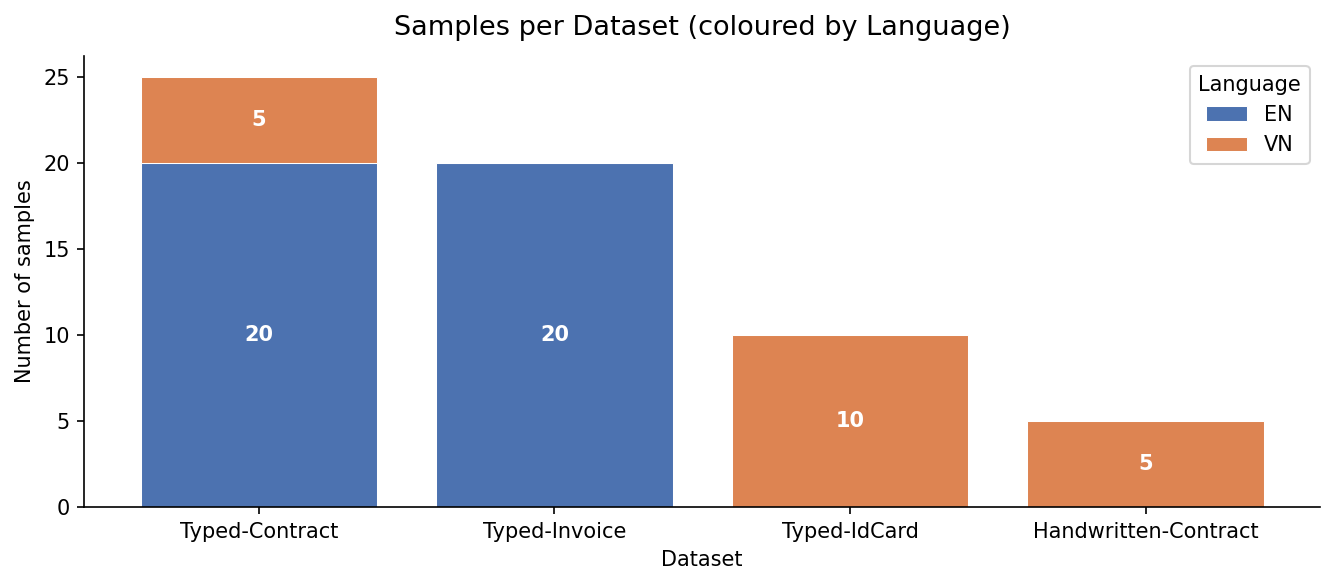

In [4]:
# Color each bar by lang
dataset_lang = df.groupby(["dataset", "lang"]).size().reset_index(name="count")
order = df.groupby("dataset").size().sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(9, 4))
bottom = {d: 0 for d in order}
for lang, grp in dataset_lang.groupby("lang"):
    vals = [grp.set_index("dataset")["count"].get(d, 0) for d in order]
    bars = ax.bar(order, vals, bottom=[bottom[d] for d in order],
                  label=lang, color=PALETTE[lang], edgecolor="white", linewidth=0.5)
    for i, (d, v) in enumerate(zip(order, vals)):
        if v > 0:
            ax.text(i, bottom[d] + v / 2, str(v), ha="center", va="center",
                    fontsize=10, color="white", fontweight="bold")
        bottom[d] += v

ax.set_xlabel("Dataset")
ax.set_ylabel("Number of samples")
ax.set_title("Samples per Dataset (coloured by Language)", fontsize=13, pad=10)
ax.legend(title="Language")
plt.tight_layout()
save("fig1_samples_per_dataset")
plt.show()

**Nhận xét:** Tập con `Typed-Contract` chiếm nhiều nhất với 25 mẫu (gồm 20 mẫu tiếng Anh và 5 mẫu tiếng Việt), theo sau là `Typed-Invoice` (20) và `Typed-IdCard` (10); `Handwritten-Contract` ít nhất với 5 mẫu. Phân bố nghiêng về hợp đồng và hóa đơn — đây cũng là hai loại tài liệu có nguồn dữ liệu công khai dồi dào nhất.

## 4. Chart 2 — Language Distribution (pie)

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig2_language_distribution.png


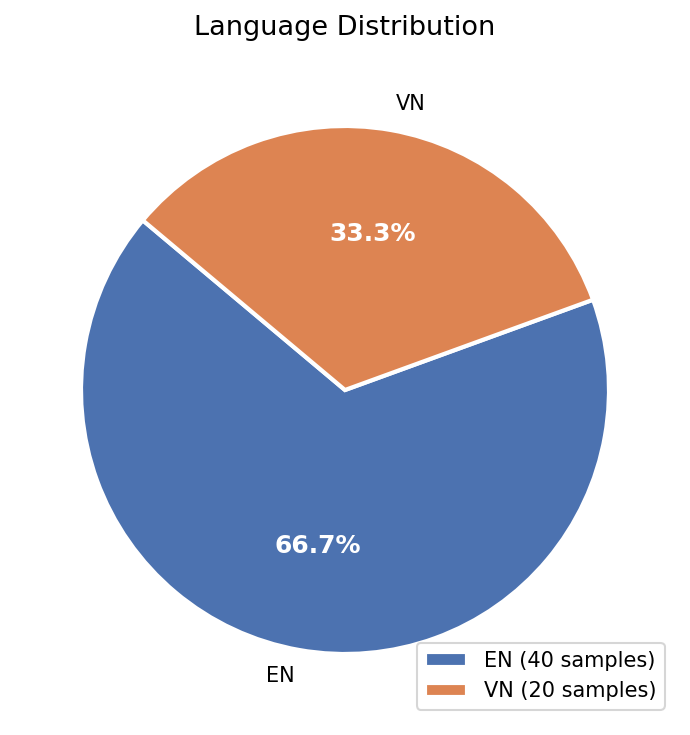

In [5]:
lang_counts = df["lang"].value_counts()

fig, ax = plt.subplots(figsize=(5, 5))
wedges, texts, autotexts = ax.pie(
    lang_counts,
    labels=lang_counts.index,
    autopct="%1.1f%%",
    colors=[PALETTE[l] for l in lang_counts.index],
    startangle=140,
    wedgeprops=dict(edgecolor="white", linewidth=2),
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_color("white")
    at.set_fontweight("bold")
ax.set_title("Language Distribution", fontsize=13, pad=12)
# Add absolute counts in legend
ax.legend(
    [f"{l} ({c} samples)" for l, c in lang_counts.items()],
    loc="lower right", fontsize=10
)
plt.tight_layout()
save("fig2_language_distribution")
plt.show()

**Nhận xét:** Dữ liệu tiếng Anh chiếm khoảng hai phần ba (40/60 ≈ 66,7%), tiếng Việt một phần ba (20/60 ≈ 33,3%). Sự chênh lệch này phản ánh thực tế nguồn dữ liệu công khai cho tiếng Anh phong phú hơn nhiều, trong khi dữ liệu tiếng Việt phần lớn phải tự thu thập nên số lượng hạn chế hơn.

## 5. Chart 3 — Doc Type Distribution

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig3_doctype_distribution.png


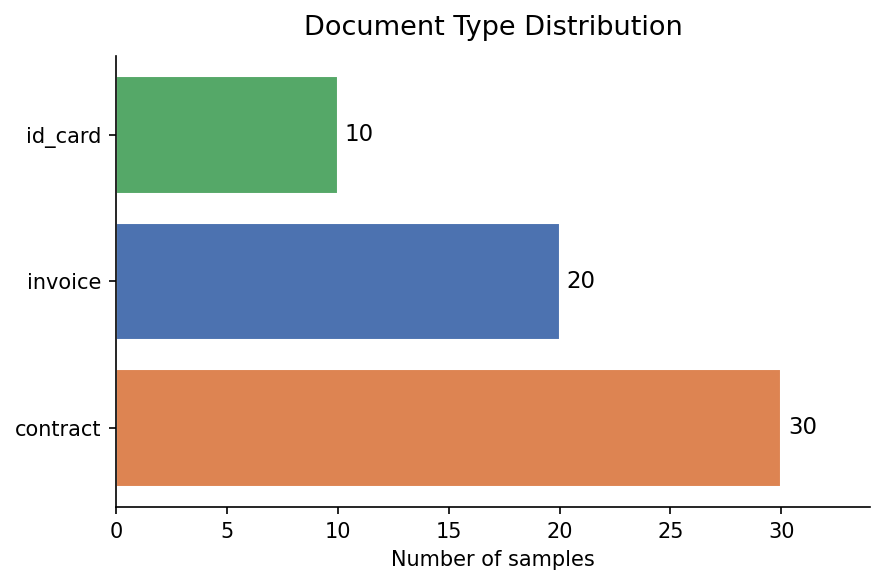

In [6]:
dtype_counts = df["doc_type"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.barh(
    dtype_counts.index,
    dtype_counts.values,
    color=[PALETTE[t] for t in dtype_counts.index],
    edgecolor="white",
)
for bar, val in zip(bars, dtype_counts.values):
    ax.text(val + 0.3, bar.get_y() + bar.get_height() / 2,
            str(val), va="center", fontsize=11)
ax.set_xlabel("Number of samples")
ax.set_title("Document Type Distribution", fontsize=13, pad=10)
ax.set_xlim(0, dtype_counts.max() + 4)
plt.tight_layout()
save("fig3_doctype_distribution")
plt.show()

**Nhận xét:** Hợp đồng (contract) là loại tài liệu phổ biến nhất với 30 mẫu (50%), tiếp theo là hóa đơn (invoice) 20 mẫu (33,3%) và căn cước công dân (id\_card) 10 mẫu (16,7%). Hợp đồng được ưu tiên vì có mặt ở cả hai ngôn ngữ và cả hai dạng văn bản (typed lẫn handwritten), thuận lợi cho việc phân tích chéo.

## 6. Chart 4 — Subtype Distribution

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig4_subtype_distribution.png


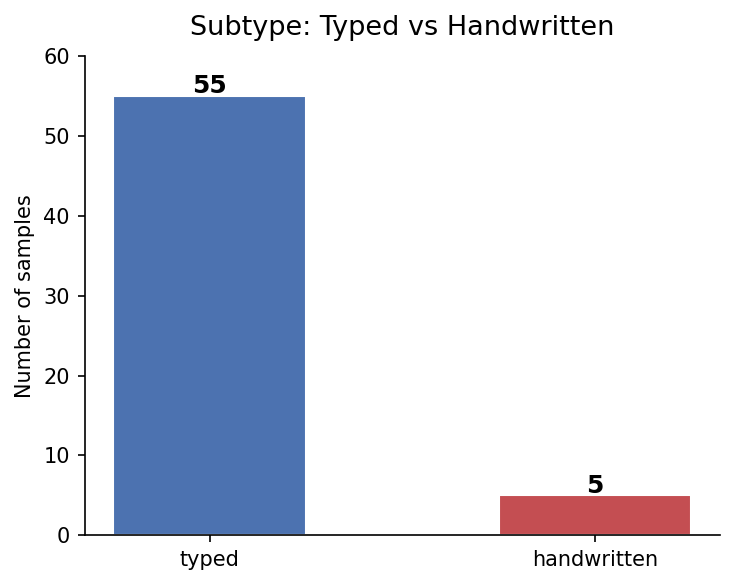

In [7]:
subtype_counts = df["subtype"].value_counts()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(
    subtype_counts.index,
    subtype_counts.values,
    color=[PALETTE[s] for s in subtype_counts.index],
    edgecolor="white",
    width=0.5,
)
for bar, val in zip(bars, subtype_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.3,
            str(val), ha="center", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of samples")
ax.set_title("Subtype: Typed vs Handwritten", fontsize=13, pad=10)
ax.set_ylim(0, subtype_counts.max() + 5)
plt.tight_layout()
save("fig4_subtype_distribution")
plt.show()

**Nhận xét:** Văn bản đánh máy (typed) áp đảo với 55 mẫu (91,7%), trong khi viết tay (handwritten) chỉ có 5 mẫu (8,3%) — toàn bộ đến từ hợp đồng mở tài khoản tiếng Việt. Đây là hạn chế cần lưu ý: số mẫu handwritten nhỏ nên kết quả đánh giá độ bền (robustness) trên dạng viết tay chỉ mang tính tham khảo, chưa đủ để kết luận thống kê mạnh.

## 7. Chart 5 — Data Source Distribution (pie)

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig5_source_distribution.png


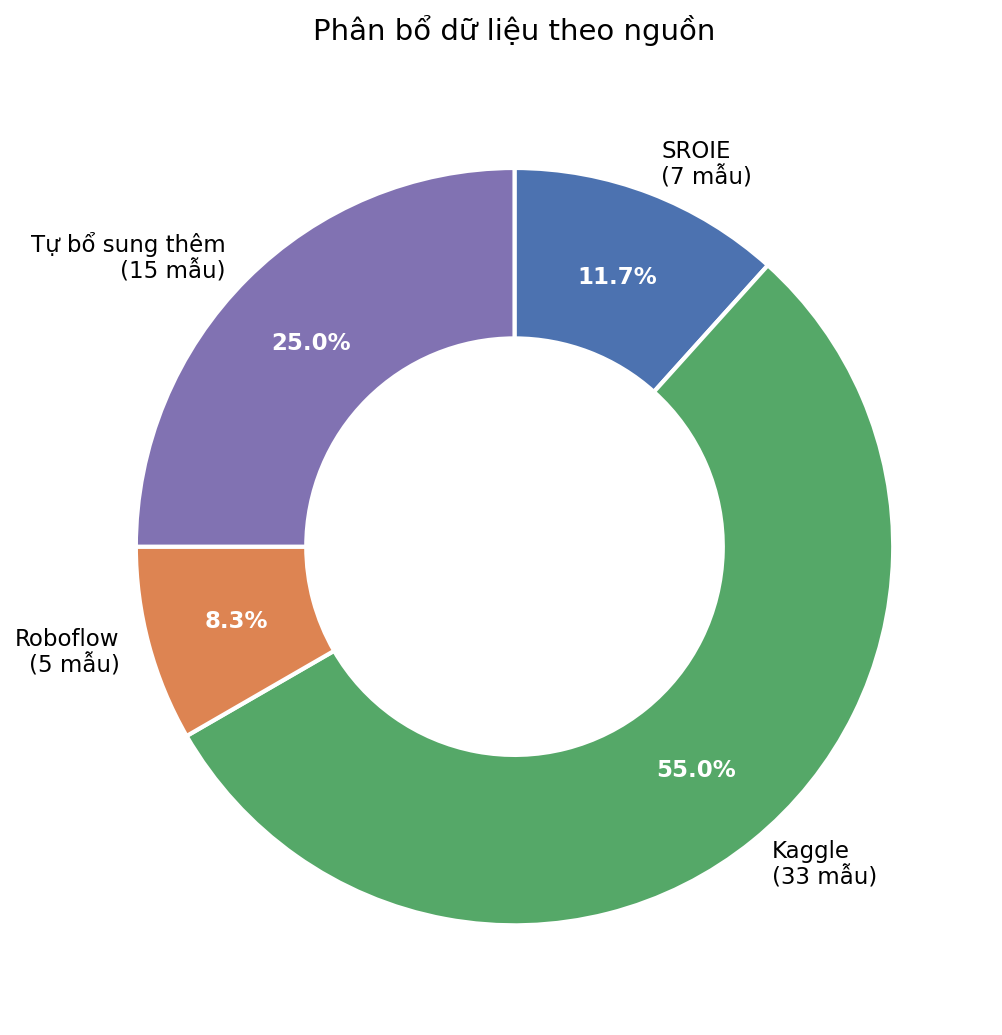

In [8]:
SOURCE_PALETTE = {
    "SROIE":           "#4C72B0",   # public — EN invoice
    "Kaggle":          "#55A868",   # public — EN invoice + contract
    "Roboflow":        "#DD8452",   # public — VN CCCD
    "Tự bổ sung thêm": "#8172B2",   # tự thu thập — VN bank docs
}
SOURCE_ORDER = list(SOURCE_PALETTE.keys())

src_counts = df.groupby("source").size().reindex(SOURCE_ORDER).dropna().astype(int)

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    src_counts,
    labels=[f"{s}\n({c} mẫu)" for s, c in src_counts.items()],
    autopct="%1.1f%%",
    colors=[SOURCE_PALETTE[s] for s in src_counts.index],
    startangle=90,
    counterclock=False,
    pctdistance=0.76,
    labeldistance=1.08,
    wedgeprops=dict(edgecolor="white", linewidth=2, width=0.45),  # donut
    textprops=dict(fontsize=11),
)
for at in autotexts:
    at.set_color("white")
    at.set_fontweight("bold")
    at.set_fontsize(11)
ax.set_title("Phân bổ dữ liệu theo nguồn", fontsize=14, pad=16)
plt.tight_layout()
save("fig5_source_distribution")
plt.show()

**Nhận xét:** Kaggle là nguồn đóng góp lớn nhất với 33 mẫu (55%), kế đến là phần tự thu thập 15 mẫu (25%), SROIE 7 mẫu (11,7%) và Roboflow 5 mẫu (8,3%). Như vậy ba phần tư dữ liệu đến từ các bộ công khai, một phần tư do tác giả tự thu thập — và toàn bộ phần tự thu thập đều là tài liệu tiếng Việt, bù đắp cho sự thiếu hụt dữ liệu công khai ở ngôn ngữ này.

## 8. Chart 6 — Language × Document Type

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig6_lang_x_doctype.png


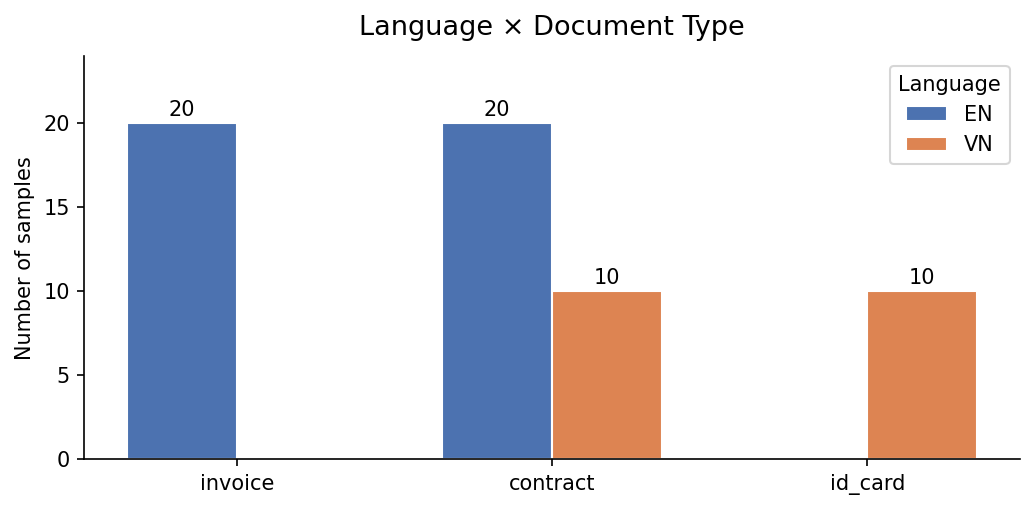

In [9]:
cross = df.groupby(["lang", "doc_type"]).size().unstack(fill_value=0)
doc_type_order = ["invoice", "contract", "id_card", "custom"]
cross = cross.reindex(columns=[c for c in doc_type_order if c in cross.columns])

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(cross.columns))
width = 0.35
for i, (lang, row) in enumerate(cross.iterrows()):
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, row.values, width, label=lang,
                  color=PALETTE[lang], edgecolor="white")
    for bar, val in zip(bars, row.values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.2, str(val),
                    ha="center", va="bottom", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(cross.columns)
ax.set_ylabel("Number of samples")
ax.set_title("Language × Document Type", fontsize=13, pad=10)
ax.legend(title="Language")
ax.set_ylim(0, cross.values.max() + 4)
plt.tight_layout()
save("fig6_lang_x_doctype")
plt.show()

**Nhận xét:** Dữ liệu tiếng Anh tập trung vào hóa đơn (20) và hợp đồng (20), còn tiếng Việt trải đều giữa hợp đồng (10) và căn cước công dân (10). Đáng chú ý, tiếng Việt không có mẫu hóa đơn còn tiếng Anh không có mẫu CCCD — sự phân bố loại tài liệu lệch nhau giữa hai ngôn ngữ này cần được tính đến khi so sánh hiệu năng theo ngôn ngữ.

## 9. Chart 7 — Dataset Overview

Saved → D:\MasterDegree\LVTN\notebooks\figures\fig7_dataset_overview.png


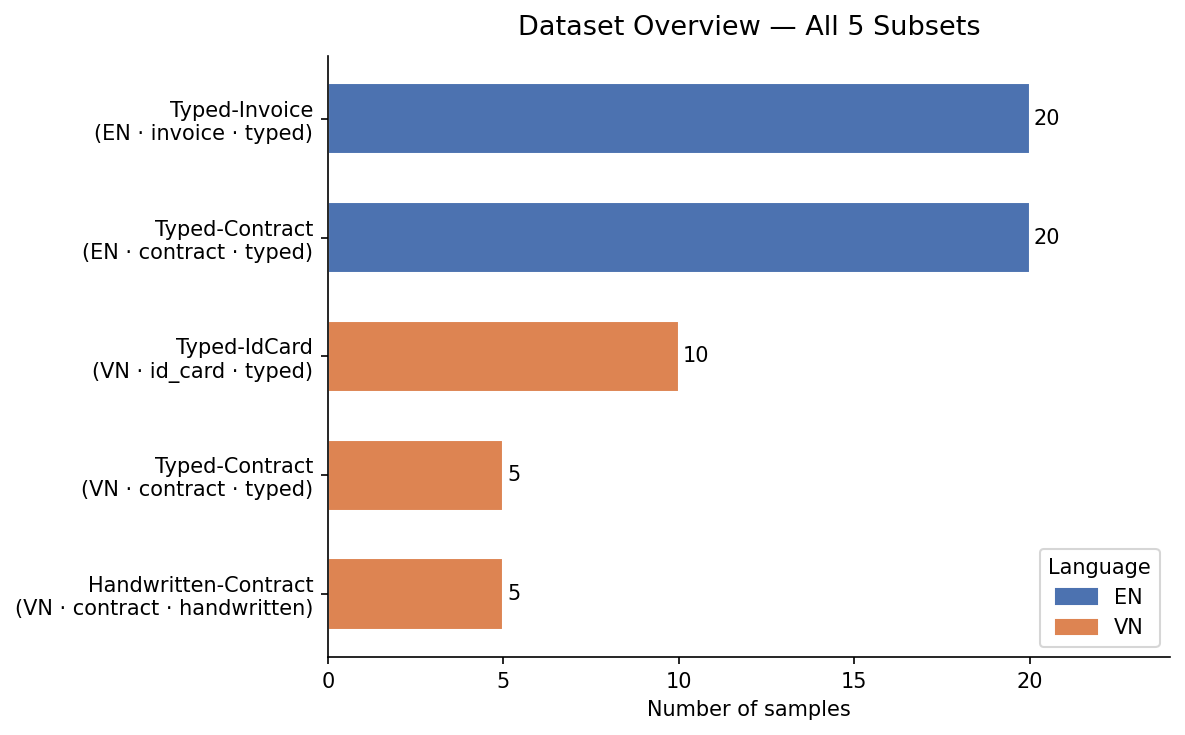

In [10]:
dataset_info = (
    df.groupby(["dataset", "lang", "doc_type", "subtype"])
    .size()
    .reset_index(name="samples")
)
dataset_info["label"] = dataset_info.apply(
    lambda r: f"{r['dataset']}\n({r['lang']} · {r['doc_type']} · {r['subtype']})", axis=1
)
dataset_info = dataset_info.sort_values("samples", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = [PALETTE[r["lang"]] for _, r in dataset_info.iterrows()]
bars = ax.barh(dataset_info["label"], dataset_info["samples"],
               color=colors, edgecolor="white", height=0.6)
for bar, val in zip(bars, dataset_info["samples"]):
    ax.text(val + 0.1, bar.get_y() + bar.get_height() / 2,
            str(val), va="center", fontsize=10)

patches = [mpatches.Patch(color=PALETTE[l], label=l) for l in ["EN", "VN"]]
ax.legend(handles=patches, title="Language", loc="lower right")
ax.set_xlabel("Number of samples")
ax.set_title("Dataset Overview — All 5 Subsets", fontsize=13, pad=10)
ax.set_xlim(0, dataset_info["samples"].max() + 4)
plt.tight_layout()
save("fig7_dataset_overview")
plt.show()

**Nhận xét:** Biểu đồ tổng hợp 5 tập con với đầy đủ ngữ cảnh (ngôn ngữ · loại tài liệu · dạng văn bản). Hai tập tiếng Anh (màu xanh) có quy mô lớn nhất (20 mẫu mỗi tập); ba tập tiếng Việt (màu cam) nhỏ hơn, trong đó `Handwritten-Contract` là tập viết tay duy nhất của toàn bộ benchmark.

## 10. Summary Table

In [11]:
summary = (
    df.groupby(["lang", "dataset", "doc_type", "subtype", "source"])
    .agg(samples=("doc_name", "count"))
    .reset_index()
)
print(summary.to_string(index=False))

lang              dataset doc_type     subtype          source  samples
  EN       Typed-Contract contract       typed          Kaggle       20
  EN        Typed-Invoice  invoice       typed          Kaggle       13
  EN        Typed-Invoice  invoice       typed           SROIE        7
  VN Handwritten-Contract contract handwritten Tự bổ sung thêm        5
  VN       Typed-Contract contract       typed Tự bổ sung thêm        5
  VN         Typed-IdCard  id_card       typed        Roboflow        5
  VN         Typed-IdCard  id_card       typed Tự bổ sung thêm        5


## 11. All figures saved

```
notebooks/figures/
  fig1_samples_per_dataset.png    — stacked bar: count per dataset, coloured by lang
  fig2_language_distribution.png  — pie: EN vs VN
  fig3_doctype_distribution.png   — horizontal bar: doc_type counts
  fig4_subtype_distribution.png   — bar: typed vs handwritten
  fig5_source_distribution.png    — donut pie: distribution by data source (4 nhóm nguồn)
  fig6_lang_x_doctype.png         — grouped bar: lang × doc_type
  fig7_dataset_overview.png       — horizontal bar: all 5 subsets annotated
```